using /kaggle/input/datasets/workplace123/final-df-v2/final_df_v2.csv


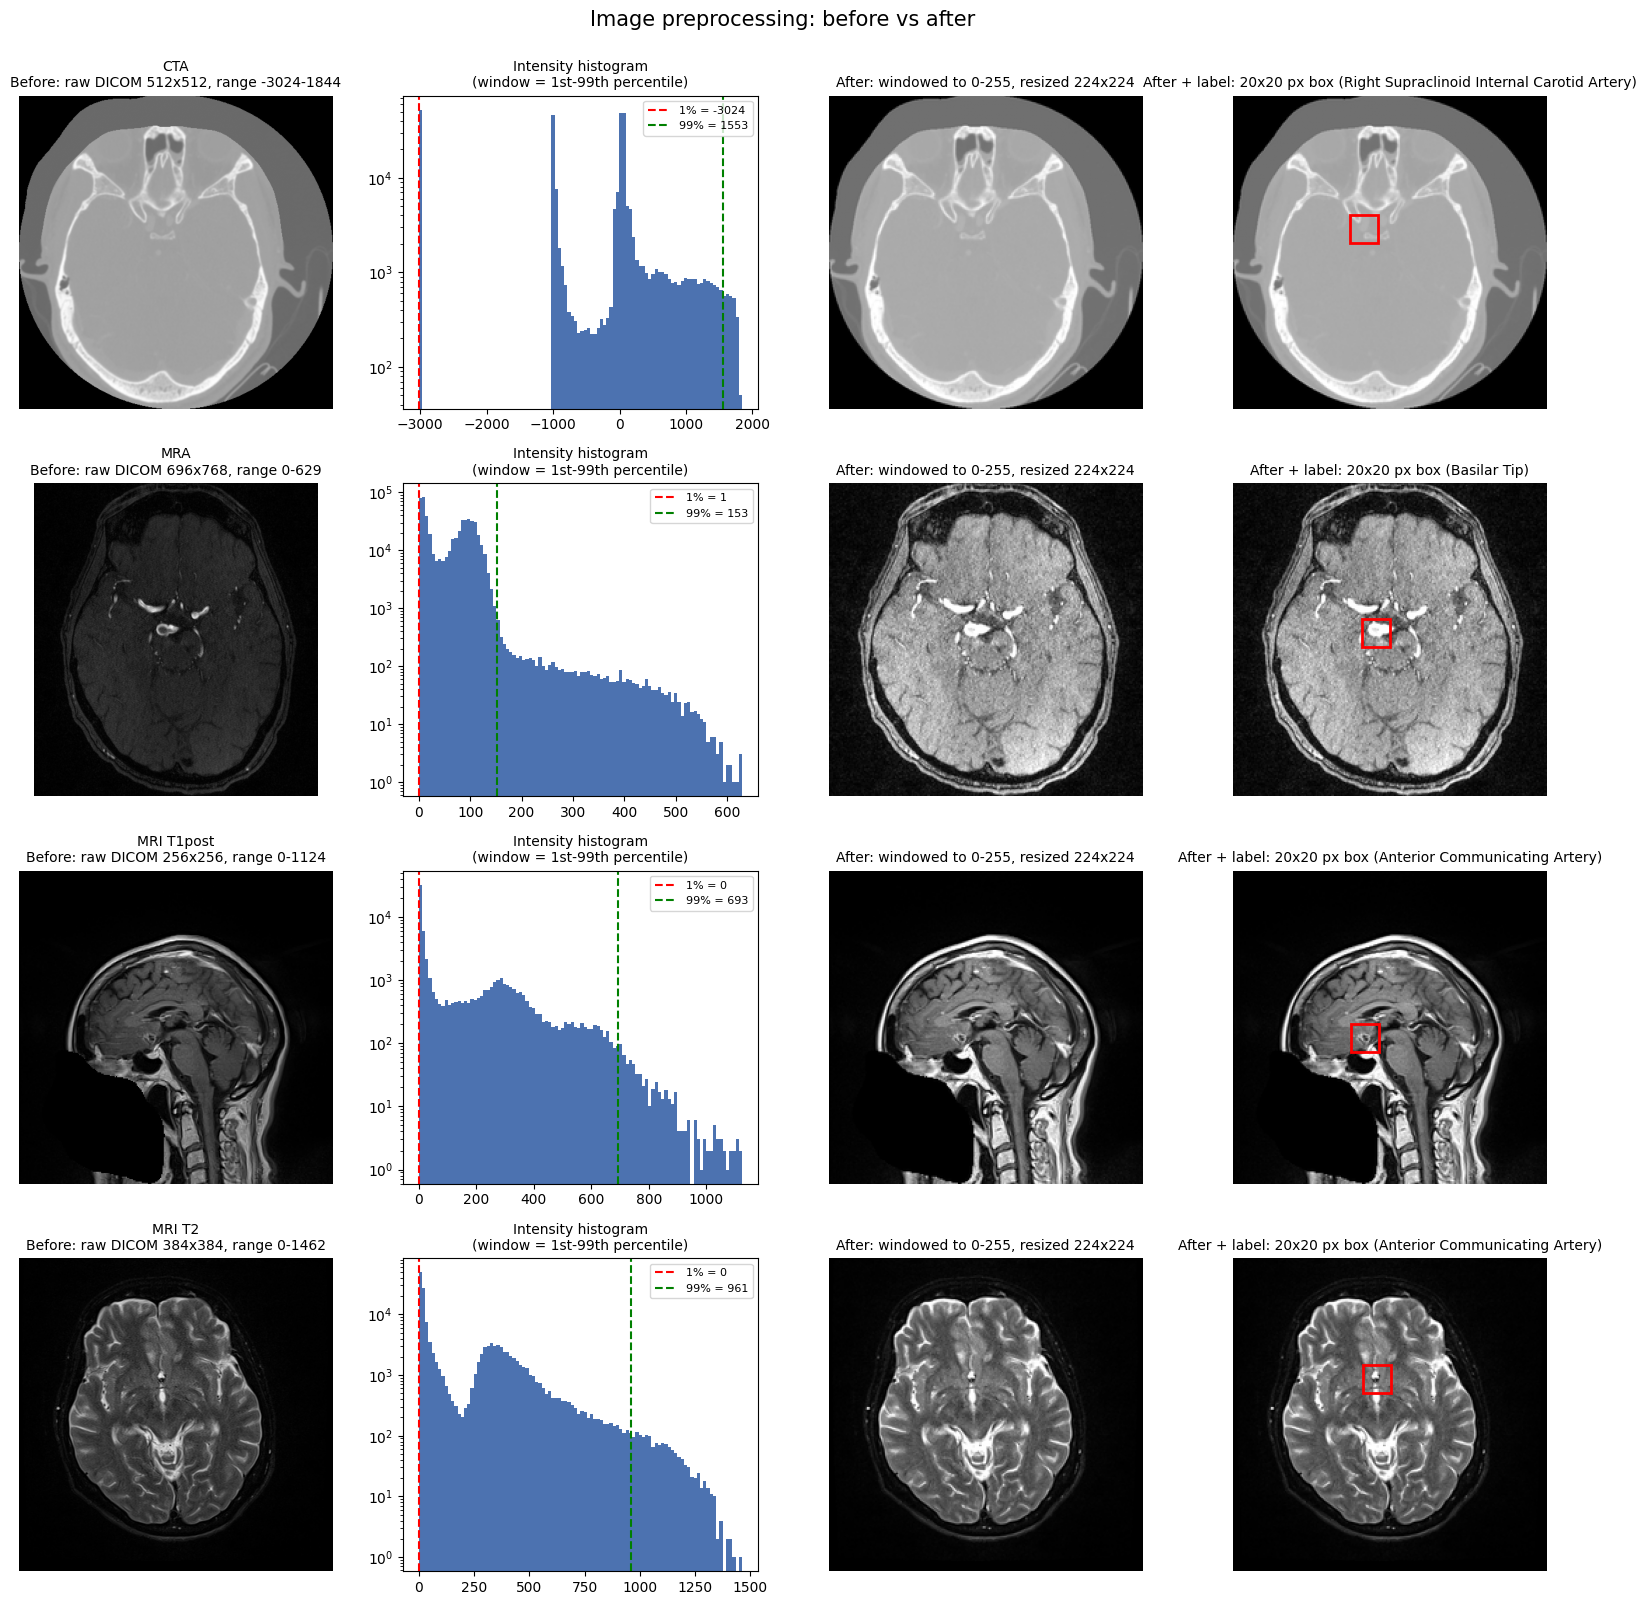

In [1]:
import os, glob, ast, numpy as np, pandas as pd, pydicom
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

IMG_SIZE, BOX = 224, 20
COMP = "/kaggle/input/competitions/rsna-intracranial-aneurysm-detection"
PNG_BASE = "/kaggle/input/datasets/dennisfong/rsna-2025-intracranial-aneurysm-png-224x224"
hits = [p for pat in ["/kaggle/working/final_df_v2.csv", "/kaggle/input/*/final_df_v2.csv", "/kaggle/input/*/*/final_df_v2.csv",
                      "/kaggle/input/*/*/*/final_df_v2.csv"] for p in glob.glob(pat)]
assert hits, "final_df_v2.csv not found"
print("using", hits[0])
final = pd.read_csv(hits[0])
smap = pd.read_csv(f"{PNG_BASE}/series_index_mapping.csv")
smap["dicom_filename"] = smap["dicom_filename"].str.replace("/kaggle/input/rsna-intracranial-aneurysm-detection", COMP, regex=False)
sop2dcm = dict(zip(smap["SOPInstanceUID"], smap["dicom_filename"]))

def window(arr):
    p1, p99 = np.percentile(arr, [1, 99])
    out = (np.clip(arr, p1, p99) - p1) / (p99 - p1) * 255.0 if p99 > p1 else np.zeros_like(arr)
    return out.astype(np.uint8), p1, p99

pos = final[final["Aneurysm Present"] == 1]
rng = np.random.default_rng(3)
mods = ["CTA", "MRA", "MRI T1post", "MRI T2"]
fig, axes = plt.subplots(len(mods), 4, figsize=(16, 4 * len(mods)))
for i, m in enumerate(mods):
    cand = pos[pos["Modality"] == m]
    cand = cand[cand["SOPInstanceUID"].isin(sop2dcm)]
    row = cand.iloc[int(rng.integers(len(cand)))]
    raw = pydicom.dcmread(sop2dcm[row["SOPInstanceUID"]]).pixel_array.astype(np.float32)
    if raw.ndim == 3: raw = raw[raw.shape[0] // 2]
    proc, p1, p99 = window(raw)
    proc = np.array(Image.fromarray(proc).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS))
    ax = axes[i]
    ax[0].imshow(raw, cmap="gray"); ax[0].set_title(f"{m}\nBefore: raw DICOM {raw.shape[1]}x{raw.shape[0]}, range {raw.min():.0f}-{raw.max():.0f}", fontsize=10)
    ax[1].hist(raw.ravel(), bins=100, color="#4C72B0"); ax[1].set_yscale("log")
    ax[1].axvline(p1, color="r", ls="--", label=f"1% = {p1:.0f}"); ax[1].axvline(p99, color="g", ls="--", label=f"99% = {p99:.0f}")
    ax[1].set_title("Intensity histogram\n(window = 1st-99th percentile)", fontsize=10); ax[1].legend(fontsize=8)
    ax[2].imshow(proc, cmap="gray", vmin=0, vmax=255); ax[2].set_title(f"After: windowed to 0-255, resized {IMG_SIZE}x{IMG_SIZE}", fontsize=10)
    ax[3].imshow(proc, cmap="gray", vmin=0, vmax=255)
    cx, cy = row["x_center"] * IMG_SIZE, row["y_center"] * IMG_SIZE
    ax[3].add_patch(Rectangle((cx - BOX / 2, cy - BOX / 2), BOX, BOX, fill=False, ec="red", lw=2))
    ax[3].set_title(f"After + label: {BOX}x{BOX} px box ({row['location']})", fontsize=10)
    for k in (0, 2, 3): ax[k].axis("off")
fig.suptitle("Image preprocessing: before vs after", fontsize=15, y=1.0)
fig.tight_layout(); os.makedirs("/kaggle/working/prep", exist_ok=True)
fig.savefig("/kaggle/working/prep/fig_preprocessing_before_after.png", dpi=150, bbox_inches="tight"); plt.show()